## Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import utils
import seaborn as sns
from pathlib import Path
import scipy.stats as stats

path_figs = "./Figs/"
Path(path_figs).mkdir(parents=True, exist_ok=True)

index_finger = utils.index_finger
conditions = utils.conditions
force_error_col = f'forceError{index_finger}'

epoch_order = ['washout', 'adaptation', 'test']
epoch_labels = {'washout': 'Washout', 'adaptation': 'Training', 'test': 'Test'}

# Fill in after collection, or leave None to keep every subject in subjs.csv
sub_nums = None

# sub_nums = [4]

utils.set_figure_style("1col")
sns.color_palette('colorblind')


[(0.00392156862745098, 0.45098039215686275, 0.6980392156862745),
 (0.8705882352941177, 0.5607843137254902, 0.0196078431372549),
 (0.00784313725490196, 0.6196078431372549, 0.45098039215686275),
 (0.8352941176470589, 0.3686274509803922, 0.0),
 (0.8, 0.47058823529411764, 0.7372549019607844),
 (0.792156862745098, 0.5686274509803921, 0.3803921568627451),
 (0.984313725490196, 0.6862745098039216, 0.8941176470588236),
 (0.5803921568627451, 0.5803921568627451, 0.5803921568627451),
 (0.9254901960784314, 0.8823529411764706, 0.2),
 (0.33725490196078434, 0.7058823529411765, 0.9137254901960784)]

In [2]:
# reload utils
import importlib
importlib.reload(utils)


<module 'utils' from '/Users/amin/projects/LearningDynamics/ChordAdaptationDynamics/SingleFingerGainGeneralizationV2/utils.py'>

Load trial-level data from `DatPreProcessing.ipynb`.

Motor-space force error = `endForce/gain − targetForce/gain`
(`.dat` `endForce` is the gain-scaled visual cursor; `targetForce` is the visual target).

Plots are split by `adaptation_condition` (the target trained in that cycle).


In [3]:
subjs_path = utils.path_misc + 'subjs.csv'
if not Path(subjs_path).exists():
    raise FileNotFoundError(
        f"{subjs_path} not found. Run DatPreProcessing.ipynb after .dat files are copied in."
    )

subjs = pd.read_csv(subjs_path, sep='\t')

if sub_nums is not None:
    subjs = subjs[subjs['subNum'].isin(sub_nums)].reset_index(drop=True)

subjs_correct = utils.remove_error_trials(subjs).copy()
subjs_correct['epoch'] = pd.Categorical(
    subjs_correct['block_type'].map(epoch_labels),
    categories=[epoch_labels[e] for e in epoch_order],
    ordered=True,
)
subjs_correct['block_type'] = pd.Categorical(
    subjs_correct['block_type'], categories=epoch_order, ordered=True,
)
subjs_correct


,subNum,BN,TN,TotalTrialNum,trial_num_within_block,trial_num_within_condition,cycle,block_type,adaptation_condition,targetForce1,...,gain,forceGain,trialCorr,trialErrorType,num_targets,chord,condition,day,count,epoch
0,1,1,1,1,1,1,1,washout,4.0,0.0,...,1.0,1.0,1,0,1,-^---,4.0,1,1,Washout
1,1,1,2,2,2,1,1,washout,4.0,0.0,...,1.0,1.0,1,0,1,-^---,2.0,1,1,Washout
2,1,1,3,3,3,1,1,washout,4.0,0.0,...,1.0,1.0,1,0,1,-v---,-4.0,1,1,Washout
3,1,1,4,4,4,2,1,washout,4.0,0.0,...,1.0,1.0,1,0,1,-v---,-4.0,1,1,Washout
4,1,1,5,5,5,1,1,washout,4.0,0.0,...,1.0,1.0,1,0,1,-v---,-2.0,1,1,Washout
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4474,8,12,55,555,55,15,4,test,4.0,0.0,...,1.0,1.0,1,0,1,-^---,4.0,1,1,Test
4475,8,12,56,556,56,12,4,test,4.0,0.0,...,1.0,1.0,1,0,1,-^---,2.0,1,1,Test
4476,8,12,57,557,57,13,4,test,4.0,0.0,...,1.0,1.0,1,0,1,-^---,2.0,1,1,Test
4477,8,12,58,558,58,14,4,test,4.0,0.0,...,1.0,1.0,1,0,1,-^---,2.0,1,1,Test


In [4]:
subjs_correct.columns

Index(['subNum', 'BN', 'TN', 'TotalTrialNum', 'trial_num_within_block',
       'trial_num_within_condition', 'cycle', 'block_type',
       'adaptation_condition', 'targetForce1', 'targetForce2', 'targetForce3',
       'targetForce4', 'targetForce5', 'endForce1', 'endForce2', 'endForce3',
       'endForce4', 'endForce5', 'producedForce1', 'producedForce2',
       'producedForce3', 'producedForce4', 'producedForce5', 'expectedForce1',
       'expectedForce2', 'expectedForce3', 'expectedForce4', 'expectedForce5',
       'forceError1', 'forceError2', 'forceError3', 'forceError4',
       'forceError5', 'isTargetVisible', 'gain', 'forceGain', 'trialCorr',
       'trialErrorType', 'num_targets', 'chord', 'condition', 'day', 'count',
       'epoch'],
      dtype='str')

### Error rates


In [5]:
subjs_err = (
    subjs.groupby(['subNum', 'block_type', 'trialCorr'])
    .size()
    .reset_index(name='num_trials')
    .sort_values(['subNum', 'block_type', 'trialCorr'])
)
subjs_err


,subNum,block_type,trialCorr,num_trials
0,1,adaptation,0,10
1,1,adaptation,1,150
2,1,test,0,16
3,1,test,1,224
4,1,washout,0,13
5,1,washout,1,147
6,2,adaptation,0,17
7,2,adaptation,1,143
8,2,test,0,21
9,2,test,1,219


## Index force error by adaptation condition

One figure per trained target (`adaptation_condition`). Panels: washout, training, test.
Lines are the trial target (`condition`); group mean ± SEM.


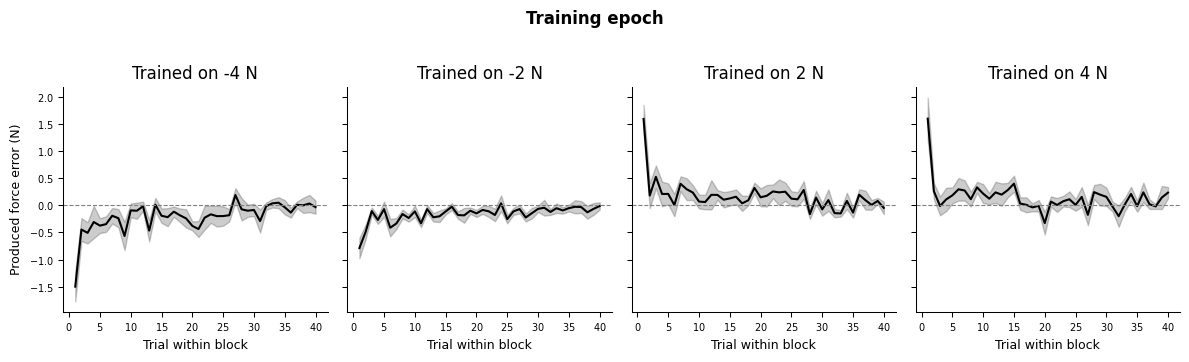

In [6]:
# Training (adaptation) only — one panel per trained target


fig, axs = plt.subplots(1, len(conditions), figsize=(12, 3.5), sharey=True)

for idx, adapt_cond in enumerate(conditions):
    cycle_data = subjs_correct[subjs_correct['adaptation_condition'] == adapt_cond]
    if cycle_data.empty:
        continue

    epoch_data = cycle_data[cycle_data['epoch'] == 'Training']
    ax = axs[idx]
    sns.lineplot(
        data=epoch_data,
        x='trial_num_within_block',
        y='forceError2',
        errorbar='se',
        ax=ax,
        color='black',
    )
    ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
    ax.set_title(f'Trained on {adapt_cond} N')
    ax.set_xlabel('Trial within block')
    ax.set_ylabel('Produced force error (N)' if idx == 0 else '')


sns.despine()
fig.suptitle('Training epoch', y=1.02)
plt.tight_layout()
plt.savefig(path_figs + 'index_produced_force_training.pdf', bbox_inches='tight')
plt.show()


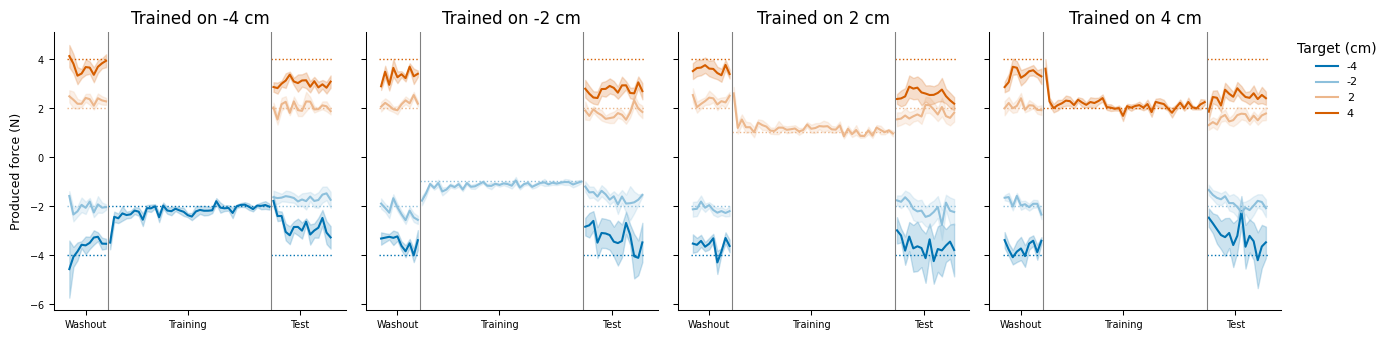

In [8]:
# Washout + training + test, one panel per trained target
from matplotlib.colors import to_rgb

def with_opacity(color, alpha, background=(1, 1, 1)):
    """Simulate alpha by blending toward the background (seaborn ignores RGBA alpha)."""
    c = np.asarray(to_rgb(color))
    bg = np.asarray(background)
    return tuple(alpha * c + (1 - alpha) * bg)

cb = sns.color_palette('colorblind')
# Negative → colorblind[0]; positive → colorblind[3]
# Larger |target| → higher opacity
condition_palette = {
    -4: with_opacity(cb[0], 1.0),
    -2: with_opacity(cb[0], 0.45),
     2: with_opacity(cb[3], 0.45),
     4: with_opacity(cb[3], 1.0),
}

n_wo = int(subjs_correct.loc[subjs_correct['epoch'] == 'Washout', 'trial_num_within_condition'].max())
n_ad = int(subjs_correct.loc[subjs_correct['epoch'] == 'Training', 'trial_num_within_block'].max())
n_te = int(subjs_correct.loc[subjs_correct['epoch'] == 'Test', 'trial_num_within_condition'].max())
epoch_offset = {'Washout': 0, 'Training': n_wo, 'Test': n_wo + n_ad}

plot_data = subjs_correct.copy()
plot_data['trial_x'] = np.where(
    plot_data['epoch'] == 'Training',
    epoch_offset['Training'] + plot_data['trial_num_within_block'],
    plot_data['epoch'].map(epoch_offset).astype(int) + plot_data['trial_num_within_condition'],
)

fig, axs = plt.subplots(1, len(conditions), figsize=(14, 3.5), sharey=True)
for idx, adapt_cond in enumerate(conditions):
    ax = axs[idx]
    cycle_data = plot_data[plot_data['adaptation_condition'] == adapt_cond]
    if cycle_data.empty:
        continue

    for epoch in ['Washout', 'Training', 'Test']:
        epoch_data = cycle_data[cycle_data['epoch'] == epoch]
        if epoch_data.empty:
            continue
        sns.lineplot(
            data=epoch_data,
            x='trial_x',
            y='producedForce2',
            hue='condition',
            hue_order=conditions,
            palette=condition_palette,
            errorbar='se',
            ax=ax,
            legend=(idx == len(conditions) - 1 and epoch == 'Test'),
        )



    # expected produced force: washout/test at the target; training at target / gain
    for cond in conditions:
        ax.hlines(cond, 0.5, n_wo + 0.5,
                  colors=condition_palette[cond], linestyles=':', linewidth=1.0, zorder=0)
        ax.hlines(cond, n_wo + n_ad + 0.5, n_wo + n_ad + n_te + 0.5,
                  colors=condition_palette[cond], linestyles=':', linewidth=1.0, zorder=0)
    ax.hlines(adapt_cond / 2, n_wo + 0.5, n_wo + n_ad + 0.5,
              colors=condition_palette[adapt_cond], linestyles=':', linewidth=1.0, zorder=0)

    ax.axvline(n_wo + 0.5, color='gray', linewidth=0.8)
    ax.axvline(n_wo + n_ad + 0.5, color='gray', linewidth=0.8)
    ax.set_xticks([n_wo / 2, n_wo + n_ad / 2, n_wo + n_ad + n_te / 2])
    ax.set_xticklabels(['Washout', 'Training', 'Test'])
    ax.set_xlabel('')
    ax.set_title(f'Trained on {adapt_cond} cm')
    ax.set_ylabel('Produced force (N)' if idx == 0 else '')
    if ax.legend_ is not None:
        ax.legend(title='Target (cm)', frameon=False, bbox_to_anchor=(1.02, 1), loc='upper left')

sns.despine()
plt.tight_layout()
plt.savefig(path_figs + 'index_produced_force_washout_training_test.pdf', bbox_inches='tight')
plt.show()


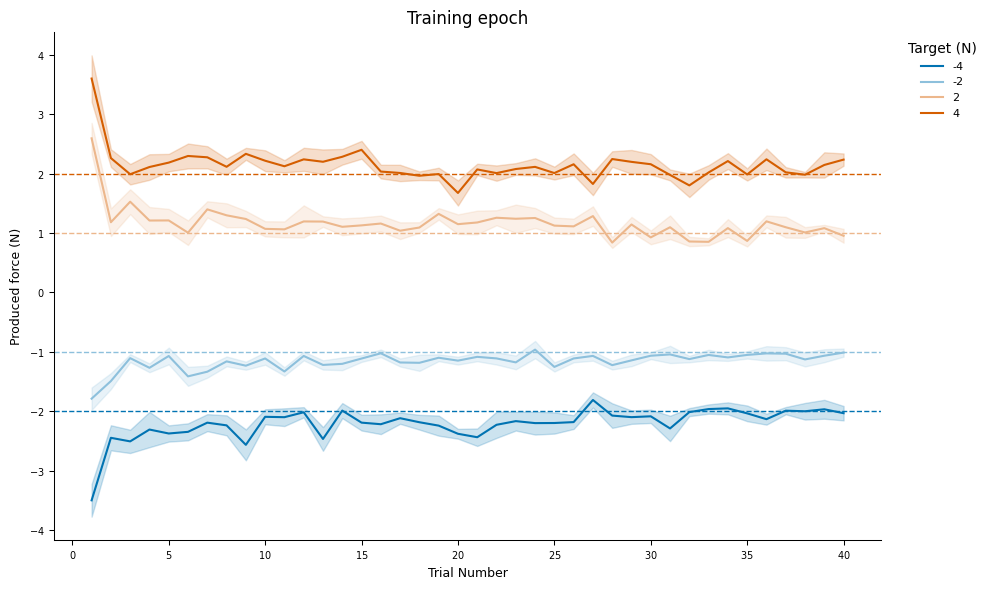

In [9]:
# Training epoch — all trained targets on one panel
from matplotlib.colors import to_rgb

def with_opacity(color, alpha, background=(1, 1, 1)):
    """Simulate alpha by blending toward the background (seaborn ignores RGBA alpha)."""
    c = np.asarray(to_rgb(color))
    bg = np.asarray(background)
    return tuple(alpha * c + (1 - alpha) * bg)

cb = sns.color_palette('colorblind')
# Negative → colorblind[0]; positive → colorblind[3]
# Larger |target| → higher opacity
condition_palette = {
    -4: with_opacity(cb[0], 1.0),
    -2: with_opacity(cb[0], 0.45),
     2: with_opacity(cb[3], 0.45),
     4: with_opacity(cb[3], 1.0),
}

train_data = subjs_correct[subjs_correct['epoch'] == 'Training']

fig, ax = plt.subplots(figsize = (10, 6))
sns.lineplot(
    data=train_data,
    x='trial_num_within_block',
    y='producedForce2',
    hue='adaptation_condition',
    hue_order=conditions,
    palette=condition_palette,
    errorbar='se',
    ax=ax,
)
for cond in conditions:
    ax.axhline(cond / 2, color=condition_palette[cond], linestyle='--', linewidth=1.0, zorder=0)
ax.set_xlabel('Trial Number')
ax.set_ylabel('Produced force (N)')
ax.set_title('Training epoch')
ax.legend(title='Target (N)', frameon=False, bbox_to_anchor=(1.02, 1), loc='upper left')
sns.despine()
plt.tight_layout()
plt.savefig(path_figs + 'index_produced_force_training_combined.pdf', bbox_inches='tight')
plt.show()


In [5]:
subjs_correct

,subNum,BN,TN,TotalTrialNum,trial_num_within_block,trial_num_within_condition,cycle,block_type,adaptation_condition,targetForce1,...,gain,forceGain,trialCorr,trialErrorType,num_targets,chord,condition,day,count,epoch
0,1,1,1,1,1,1,1,washout,4.0,0.0,...,1.0,1.0,1,0,1,-^---,4.0,1,1,Washout
1,1,1,2,2,2,1,1,washout,4.0,0.0,...,1.0,1.0,1,0,1,-^---,2.0,1,1,Washout
2,1,1,3,3,3,1,1,washout,4.0,0.0,...,1.0,1.0,1,0,1,-v---,-4.0,1,1,Washout
3,1,1,4,4,4,2,1,washout,4.0,0.0,...,1.0,1.0,1,0,1,-v---,-4.0,1,1,Washout
4,1,1,5,5,5,1,1,washout,4.0,0.0,...,1.0,1.0,1,0,1,-v---,-2.0,1,1,Washout
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4474,8,12,55,555,55,15,4,test,4.0,0.0,...,1.0,1.0,1,0,1,-^---,4.0,1,1,Test
4475,8,12,56,556,56,12,4,test,4.0,0.0,...,1.0,1.0,1,0,1,-^---,2.0,1,1,Test
4476,8,12,57,557,57,13,4,test,4.0,0.0,...,1.0,1.0,1,0,1,-^---,2.0,1,1,Test
4477,8,12,58,558,58,14,4,test,4.0,0.0,...,1.0,1.0,1,0,1,-^---,2.0,1,1,Test


### Washout vs test: median produced force by target condition

X positions use the actual target force values (spacing −4→−2→2→4 is proportional).
Solid = washout, dashed = test.


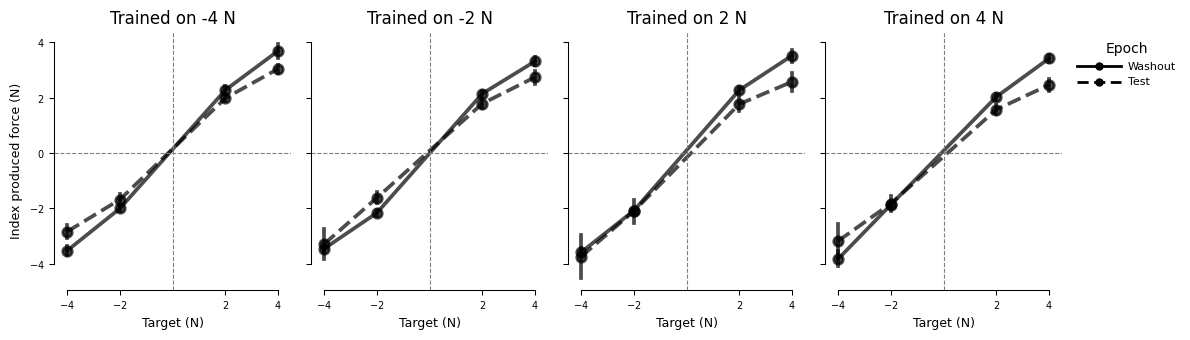

In [10]:
from matplotlib.lines import Line2D

epoch_line_style = {
    'washout': 'solid',
    'test': 'dashed',
}

fig, axs = plt.subplots(1, len(conditions), figsize=(12, 3.5), sharey=True)


for idx, adapt_cond in enumerate(conditions):
    cycle_data = subjs_correct[subjs_correct['adaptation_condition'] == adapt_cond]
    if cycle_data.empty:
        continue

    ax = axs[idx]
    for epoch, ls in epoch_line_style.items():
        epoch_data = cycle_data[cycle_data['block_type'] == epoch]
        if epoch_data.empty:
            continue
        grouped_data = (
            epoch_data.groupby(['subNum', 'condition'], as_index=False)['producedForce2']
            .median()
        )
        # native_scale keeps numeric spacing (-4,-2,2,4)
        sns.pointplot(
            data=grouped_data,
            x='condition',
            y='producedForce2',
            errorbar='se',
            native_scale=True,
            ax=ax,
            linestyles=ls,
            color='black',
            alpha=0.7,
        )

    ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
    ax.axvline(0, color='gray', linestyle='--', linewidth=0.8)
    ax.set_title(f'Trained on {adapt_cond} N')
    ax.set_xlabel('Target (N)')
    ax.set_xticks(conditions)
    ax.set_xlim(min(conditions) - 0.5, max(conditions) + 0.5)
    if idx == 0:
        ax.set_ylabel('Index produced force (N)')
    else:
        ax.set_ylabel('')

legend_handles = [
    Line2D([0], [0], color='black', linestyle='-', linewidth=2, marker='o',
           markersize=5, label='Washout'),
    Line2D([0], [0], color='black', linestyle='--', linewidth=2, marker='o',
           markersize=5, dashes=(4, 2), label='Test'),
]
leg = axs[-1].legend(
    handles=legend_handles,
    title='Epoch',
    loc='upper left',
    frameon=False,
    bbox_to_anchor=(1.02, 1),
    handlelength=4,
    handletextpad=0.6,
)


sns.despine(trim=True)
plt.tight_layout()
plt.savefig(path_figs + 'produced_force_washout_vs_test.pdf', bbox_inches='tight')
plt.show()


### Mean index force error (± SEM) by epoch, split by adaptation condition


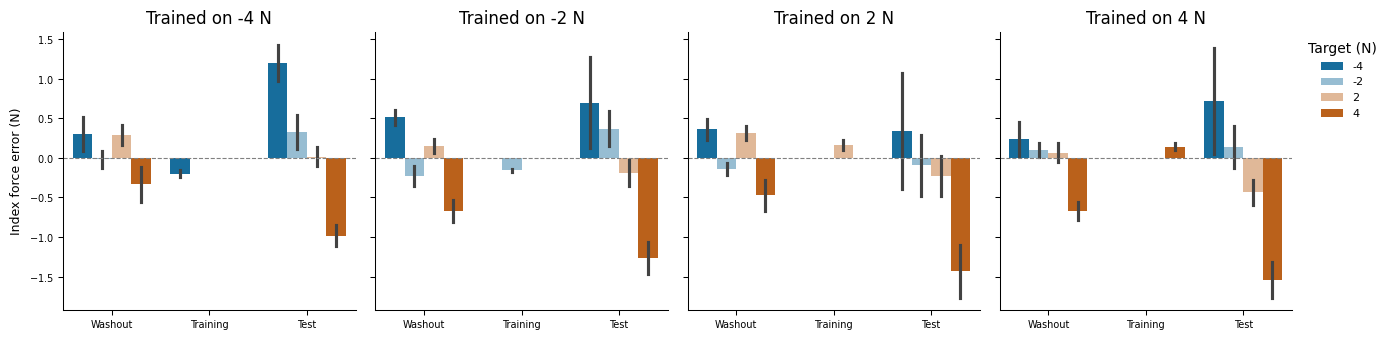

In [7]:
from matplotlib.colors import to_rgb

def with_opacity(color, alpha, background=(1, 1, 1)):
    """Simulate alpha by blending toward the background (seaborn ignores RGBA alpha)."""
    c = np.asarray(to_rgb(color))
    bg = np.asarray(background)
    return tuple(alpha * c + (1 - alpha) * bg)

cb = sns.color_palette('colorblind')
# Negative → colorblind[0]; positive → colorblind[3]
# Larger |target| → higher opacity
condition_palette = {
    -4: with_opacity(cb[0], 1.0),
    -2: with_opacity(cb[0], 0.45),
     2: with_opacity(cb[3], 0.45),
     4: with_opacity(cb[3], 1.0),
}

subj_means = (
    subjs_correct.groupby(
        ['subNum', 'adaptation_condition', 'epoch', 'condition'],
        observed=True,
    )[force_error_col]
    .mean()
    .reset_index()
)

fig, axs = plt.subplots(1, 4, figsize=(14, 3.5), sharey=True)
for ax, adapt_cond in zip(axs, conditions):
    plot_data = subj_means[subj_means['adaptation_condition'] == adapt_cond]
    sns.barplot(
        data=plot_data,
        x='epoch',
        y=force_error_col,
        hue='condition',
        hue_order=conditions,
        palette=condition_palette,
        errorbar='se',
        ax=ax,
    )
    ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
    ax.set_title(f'Trained on {adapt_cond} N')
    ax.set_xlabel('')
    ax.set_ylabel('Index force error (N)' if ax is axs[0] else '')
    if ax is not axs[-1] and ax.legend_ is not None:
        ax.legend_.remove()
    elif ax.legend_ is not None:
        ax.legend(title='Target (N)', frameon=False, bbox_to_anchor=(1.02, 1), loc='upper left')

sns.despine()
plt.tight_layout()
plt.savefig(path_figs + 'index_force_error_mean_by_adapt.pdf', bbox_inches='tight')
plt.show()


### Aftereffect: test − washout

Within each `subNum`, `adaptation_condition`, and target `condition`, subtract the washout mean from the test mean (index produced force).


In [12]:
epoch_means = (
    subjs_correct.loc[subjs_correct['epoch'].isin(['Washout', 'Test'])]
    .groupby(
        ['subNum', 'adaptation_condition', 'condition', 'epoch'],
        observed=True,
    )['producedForce2']
    .mean()
    .unstack('epoch')
)

epoch_means['test_minus_washout'] = epoch_means['Test'] - epoch_means['Washout']
aftereffect = epoch_means.reset_index()
aftereffect.iloc[:20]


epoch,subNum,adaptation_condition,condition,Washout,Test,test_minus_washout
0,1,-4.0,-4.0,-4.635800,-3.356429,1.279371
1,1,-4.0,-2.0,-2.137300,-2.212867,-0.075567
2,1,-4.0,2.0,1.897600,2.343071,0.445471
3,1,-4.0,4.0,4.337500,3.688714,-0.648786
4,1,-2.0,-4.0,-3.151900,-2.278357,0.873543
5,1,-2.0,-2.0,-2.041000,-1.472867,0.568133
6,1,-2.0,2.0,1.941111,2.141500,0.200389
7,1,-2.0,4.0,3.892857,2.597733,-1.295124
8,1,2.0,-4.0,-3.084100,-4.669154,-1.585054
9,1,2.0,-2.0,-2.308714,-3.930500,-1.621786


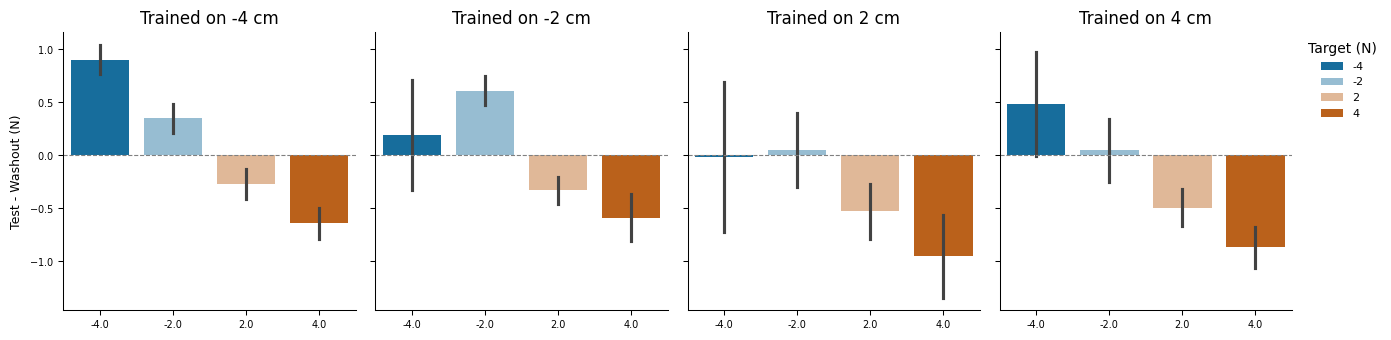

In [13]:
from matplotlib.colors import to_rgb

def with_opacity(color, alpha, background=(1, 1, 1)):
    """Simulate alpha by blending toward the background (seaborn ignores RGBA alpha)."""
    c = np.asarray(to_rgb(color))
    bg = np.asarray(background)
    return tuple(alpha * c + (1 - alpha) * bg)

cb = sns.color_palette('colorblind')
# Negative → colorblind[0]; positive → colorblind[3]
# Larger |target| → higher opacity
condition_palette = {
    -4: with_opacity(cb[0], 1.0),
    -2: with_opacity(cb[0], 0.45),
     2: with_opacity(cb[3], 0.45),
     4: with_opacity(cb[3], 1.0),
}

fig, axs = plt.subplots(1, 4, figsize=(14, 3.5), sharey=True)
for ax, adapt_cond in zip(axs, conditions):
    plot_data = aftereffect[aftereffect['adaptation_condition'] == adapt_cond]
    sns.barplot(
        data=plot_data,
        x='condition',
        y='test_minus_washout',
        hue='condition',
        hue_order=conditions,
        palette=condition_palette,
        errorbar='se',
        ax=ax,
    )
    ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
    ax.set_title(f'Trained on {adapt_cond} cm')
    ax.set_xlabel('')
    ax.set_ylabel('Test - Washout (N)' if ax is axs[0] else '')
    if ax is not axs[-1] and ax.legend_ is not None:
        ax.legend_.remove()
    elif ax.legend_ is not None:
        ax.legend(title='Target (N)', frameon=False, bbox_to_anchor=(1.02, 1), loc='upper left')

sns.despine()
plt.tight_layout()
# plt.savefig(path_figs + 'index_force_error_mean_by_adapt.pdf', bbox_inches='tight')
plt.show()


## Summary results

Compress the 4×4 aftereffect matrix into two questions about **gain-like** remapping:

1. **Panel A (extent):** Within flexion or within extension, does training one extent generalize to the other (2 ↔ 4)?
2. **Panel B (direction):** Does that aftereffect also appear in the **opposite direction**?

**Aftereffect pooling (important):** do **not** average condition-level aftereffects.
Within each participant, first pool the relevant conditions for **Washout** and for **Test** separately (using **force magnitude** `|F|`), then:

`AE_magnitude = mean(|F| Washout in pool) − mean(|F| Test in pool)`

Then `sns.barplot` averages those subject-level AEs (± SEM).


### Panel A — Same-sign extent transfer (2 ↔ 4)

First question: within flexion or within extension, does training one target generalize to the other extent?

Two plots: **Trained on 2 cm** and **Trained on 4 cm**. X-axis = test extent (`2 cm`, `4 cm`).

Raw force flips sign across flexion/extension, so before pooling +/− we use **force magnitude**:

`force_magnitude = |producedForce|`

Then within each participant × train_extent × test_extent:

`AE_magnitude = mean(force_magnitude | Washout) − mean(force_magnitude | Test)`

Positive `AE_magnitude` = smaller |force| at test than washout (gain-consistent).

**Gain prediction:** transfer tracks extent (train 2 → larger AE at 4 cm; train 4 → smaller AE at 2 cm).  
**Extent-specific:** AE mainly at the trained extent; near 0 at the other.


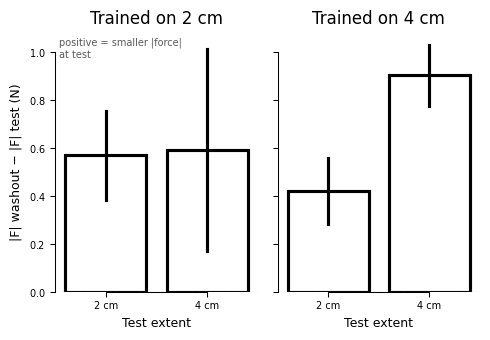

In [5]:
# --- Panel A: same-sign extent transfer (2 ↔ 4) ---
# Force magnitude so +/− can be pooled; AE = washout |F| − test |F|.

df = subjs_correct.loc[subjs_correct['epoch'].isin(['Washout', 'Test'])].copy()
same_sign = np.sign(df['adaptation_condition']) == np.sign(df['condition'])
df = df.loc[same_sign].copy()

# Force magnitude (N); positive AE_magnitude = smaller |force| at test (gain-consistent)
df['force_magnitude'] = df['producedForce2'].abs()
df['train_extent'] = df['adaptation_condition'].abs().astype(int)  # 2 or 4
df['test_extent'] = df['condition'].abs().astype(int)

# Within participant: pooled Washout |F| − pooled Test |F| at each train/test extent
epoch_pool = (
    df.groupby(['subNum', 'train_extent', 'test_extent', 'epoch'], observed=True)['force_magnitude']
    .mean()
    .unstack('epoch')
)
epoch_pool['AE_magnitude'] = epoch_pool['Washout'] - epoch_pool['Test']
panel_a = epoch_pool.reset_index()
panel_a['test_label'] = panel_a['test_extent'].map({2: '2 cm', 4: '4 cm'})

test_order = ['2 cm', '4 cm']
cb = sns.color_palette('colorblind')

fig, axs = plt.subplots(1, 2, figsize=(5, 3.5), sharey=True)

for ax, train_ext in zip(axs, [2, 4]):
    plot_data = panel_a[panel_a['train_extent'] == train_ext]

    sns.barplot(
        data=plot_data,
        x='test_label',
        y='AE_magnitude',
        order=test_order,
        errorbar='se',
        legend=False,
        ax=ax,
        fill = False,
        color = 'black'
    )

    # sns.stripplot(
    #     data=plot_data,
    #     x='test_label',
    #     y='AE_magnitude',
    #     order=test_order,
    #     ax=ax,
    #     color = 'black',
    #     # jitter = 0.2,
    #     alpha = 0.5,
    #     # size = 4
    # )

    ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
    ax.set_title(f'Trained on {train_ext} cm')
    ax.set_xlabel('Test extent')
    ax.set_ylabel('|F| washout − |F| test (N)' if ax is axs[0] else '')
    if ax is axs[0]:
        ax.annotate(
            'positive = smaller |force|\nat test',
            xy=(0.02, 0.98),
            xycoords='axes fraction',
            va='top',
            ha='left',
            fontsize=7,
            color='0.35',
        )

sns.despine(trim=True)
plt.tight_layout()
plt.savefig(path_figs + 'summary_panel_A_extent_transfer.pdf', bbox_inches='tight')
plt.show()

# panel_a.head()


### Panel B — Trained direction vs opposite direction

Second question: after training, does the magnitude aftereffect transfer to the **opposite direction** as well?

One plot, two bars (within each participant, then average across subjects):

- **Trained direction:** train and test on the same direction (flexion↔flexion or extension↔extension), extents pooled  
- **Opposite direction:** train on one direction, test on the other, extents pooled  

Using force magnitude:

`AE_magnitude = mean(|F| Washout) − mean(|F| Test)`

**Gain prediction:** both bars positive and similar (magnitude remapping in both directions).  
**Direction-specific:** trained-direction bar positive; opposite-direction near 0.


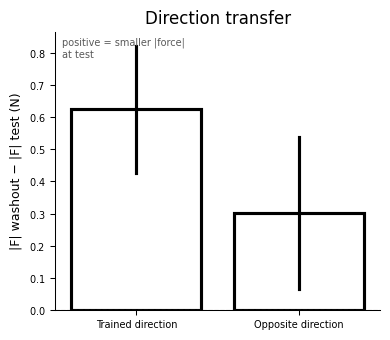

T-test trained vs opposite direction: p-value: 0.010832013833890047, t-stat: 3.4403525048629637, df: 7
T-test opposite direction vs 0: p-value: 0.2410870776758838, t-stat: 1.280730570742087, df: 7


In [6]:
# --- Panel B: trained direction vs opposite direction (force magnitude) ---
# One AE per subject × direction match: pool conditions, then washout |F| − test |F|.

df = subjs_correct.loc[subjs_correct['epoch'].isin(['Washout', 'Test'])].copy()
df['force_magnitude'] = df['producedForce2'].abs()
df['direction_match'] = np.where(
    np.sign(df['adaptation_condition']) == np.sign(df['condition']),
    'Trained direction',
    'Opposite direction',
)

# Within participant: one Washout mean and one Test mean per trained/opposite pool
epoch_pool = (
    df.groupby(['subNum', 'direction_match', 'epoch'], observed=True)['force_magnitude']
    .mean()
    .unstack('epoch')
)
epoch_pool['AE_magnitude'] = epoch_pool['Washout'] - epoch_pool['Test']
panel_b = epoch_pool.reset_index()

match_order = ['Trained direction', 'Opposite direction']

fig, ax = plt.subplots(figsize=(4, 3.5))

sns.barplot(
    data=panel_b,
    x='direction_match',
    y='AE_magnitude',
    order=match_order,
    errorbar='se',
    legend=False,
    ax=ax,
    color='black',
    fill=False,
)

ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
ax.set_title('Direction transfer')
ax.set_xlabel('')
ax.set_ylabel('|F| washout − |F| test (N)')
ax.annotate(
    'positive = smaller |force|\nat test',
    xy=(0.02, 0.98),
    xycoords='axes fraction',
    va='top',
    ha='left',
    fontsize=7,
    color='0.35',
)

sns.despine()
plt.tight_layout()
plt.savefig(path_figs + 'summary_panel_B_sign_transfer.pdf', bbox_inches='tight')
plt.show()

panel_b.head(10)


# statistical test:
# trained direction vs opposite direction
result = stats.ttest_rel(
    panel_b.loc[panel_b['direction_match'] == 'Trained direction', 'AE_magnitude'],
    panel_b.loc[panel_b['direction_match'] == 'Opposite direction', 'AE_magnitude'],
)
print(
    f"T-test trained vs opposite direction: p-value: {result.pvalue}, "
    f"t-stat: {result.statistic}, df: {result.df}"
)

# opposite direction vs 0
result = stats.ttest_1samp(
    panel_b.loc[panel_b['direction_match'] == 'Opposite direction', 'AE_magnitude'],
    0,
)
print(
    f"T-test opposite direction vs 0: p-value: {result.pvalue}, "
    f"t-stat: {result.statistic}, df: {result.df}"
)

### Test-phase drift — does |F| return toward washout during test?

If the aftereffect decays within the test block, averaging all 15 test trials underestimates it (and could mask the extent scaling predicted by gain adaptation).

Same-direction targets only (as in Panel A); flexion and extension pooled via `|F|`. Within each participant, average `|F|` at each trial number (per target), then mean ± SEM across subjects.

- **Dotted:** washout mean `|F|` for that test extent
- **Dashed:** group-average linear trend over test trials

Positive slope = `|F|` drifting up toward washout (aftereffect decaying).

In [ ]:
# --- Test-phase drift: does |F| creep back toward washout over test trials? ---
# Same-direction targets only (as in Panel A); flexion/extension pooled via |F|.

df = subjs_correct.loc[subjs_correct['epoch'].isin(['Washout', 'Test'])].copy()
same_sign = np.sign(df['adaptation_condition']) == np.sign(df['condition'])
df = df.loc[same_sign].copy()

df['force_magnitude'] = df['producedForce2'].abs()
df['train_extent'] = df['adaptation_condition'].abs().astype(int)  # 2 or 4
df['test_extent'] = df['condition'].abs().astype(int)
df['test_label'] = df['test_extent'].map({2: '2 cm', 4: '4 cm'})

# Subject mean at each trial (pools the flexion and extension cycles); SEM is across subjects
trial_means = (
    df.groupby(
        ['subNum', 'train_extent', 'test_extent', 'test_label', 'epoch', 'trial_num_within_condition'],
        observed=True,
    )['force_magnitude']
    .mean()
    .reset_index()
)

# Washout reference: pooled washout |F| per subject, then averaged across subjects
washout_ref = (
    trial_means.loc[trial_means['epoch'] == 'Washout']
    .groupby(['subNum', 'train_extent', 'test_extent'])['force_magnitude'].mean()
    .groupby(['train_extent', 'test_extent']).mean()
)

# Linear trend of |F| over test trials, per subject × train extent × test extent
test_trials = trial_means.loc[trial_means['epoch'] == 'Test']
slope_rows = []
for (sub, train_ext, test_ext), g in test_trials.groupby(['subNum', 'train_extent', 'test_extent']):
    fit = stats.linregress(g['trial_num_within_condition'], g['force_magnitude'])
    slope_rows.append({
        'subNum': sub, 'train_extent': train_ext, 'test_extent': test_ext,
        'slope': fit.slope, 'intercept': fit.intercept,
    })
drift_slopes = pd.DataFrame(slope_rows)

n_wo = int(trial_means.loc[trial_means['epoch'] == 'Washout', 'trial_num_within_condition'].max())
n_te = int(test_trials['trial_num_within_condition'].max())
gap = 2  # blank trials between washout and test on the x-axis
epoch_offset = {'Washout': 0, 'Test': n_wo + gap}
trial_means['trial_x'] = (
    trial_means['epoch'].map(epoch_offset).astype(int) + trial_means['trial_num_within_condition']
)

test_order = ['2 cm', '4 cm']
extent_palette = {'2 cm': '0.6', '4 cm': 'black'}

fig, axs = plt.subplots(1, 2, figsize=(8, 3.5), sharey=True)

for ax, train_ext in zip(axs, [2, 4]):
    for epoch in ['Washout', 'Test']:
        sns.lineplot(
            data=trial_means[(trial_means['train_extent'] == train_ext) & (trial_means['epoch'] == epoch)],
            x='trial_x',
            y='force_magnitude',
            hue='test_label',
            hue_order=test_order,
            palette=extent_palette,
            errorbar='se',
            marker='o',
            markersize=3,
            markeredgewidth=0,
            ax=ax,
            legend=(ax is axs[-1] and epoch == 'Test'),
        )

    test_x = np.arange(1, n_te + 1)
    for test_ext, label in zip([2, 4], test_order):
        # washout mean |F| extended across the test epoch
        ax.hlines(washout_ref[(train_ext, test_ext)], 0.5, n_wo + gap + n_te + 0.5,
                  colors=extent_palette[label], linestyles=':', linewidth=1.0, zorder=0)
        # group-average linear trend over test trials
        fits = drift_slopes[(drift_slopes['train_extent'] == train_ext) & (drift_slopes['test_extent'] == test_ext)]
        ax.plot(epoch_offset['Test'] + test_x, fits['intercept'].mean() + fits['slope'].mean() * test_x,
                color=extent_palette[label], linestyle='--', linewidth=1.0)

    ax.axvline(n_wo + gap / 2 + 0.5, color='gray', linewidth=0.8)
    ax.set_xticks([n_wo / 2 + 0.5, epoch_offset['Test'] + n_te / 2 + 0.5])
    ax.set_xticklabels(['Washout', 'Test'])
    ax.set_xlabel('Trial (per target)')
    ax.set_title(f'Trained on {train_ext} cm')
    ax.set_ylabel('|Produced force| (N)' if ax is axs[0] else '')
    if ax.legend_ is not None:
        ax.legend(title='Test extent', frameon=False, bbox_to_anchor=(1.02, 1), loc='upper left')

axs[0].annotate(
    'dotted = washout mean\ndashed = linear trend in test',
    xy=(0.02, 0.98),
    xycoords='axes fraction',
    va='top',
    ha='left',
    fontsize=7,
    color='0.35',
)

sns.despine()
plt.tight_layout()
plt.savefig(path_figs + 'test_drift_same_direction.pdf', bbox_inches='tight')
plt.show()

# statistical test: test-phase slope vs 0 (positive = |F| drifting up toward washout)
for (train_ext, test_ext), g in drift_slopes.groupby(['train_extent', 'test_extent']):
    result = stats.ttest_1samp(g['slope'], 0)
    print(
        f"Trained {train_ext} cm, tested {test_ext} cm: mean slope = {g['slope'].mean():.3f} N/trial, "
        f"p-value: {result.pvalue}, t-stat: {result.statistic}, df: {result.df}"
    )

## Summary results (v2) — three questions

The same force-magnitude aftereffect as above (within each participant: pool the relevant conditions, then `AE_magnitude = mean |F| washout − mean |F| test`), asked as three questions:

1. **Panel A — Is there an aftereffect at all?** Trained target, by trained extent.
2. **Panel B — How local is it?** Trained target → other extent on the same side → opposite side.
3. **Panel C — Gain or additive?** On the trained side: trained 2 → test 4 vs trained 4 → test 2.

### Panel A (v2) — Is there an aftereffect at the trained target?

Trained target only, one bar per trained extent. Under gain 2 the target needs about half the usual force, so **complete adaptation** would be an aftereffect of half the washout force; the fraction reached is printed below.

**Adaptation happened:** both bars > 0.

**In newtons the aftereffect is larger for 4 cm**, since half of a larger force is a larger correction. This is a manipulation check, not evidence for gain over additive: both accounts predict it, because the gain manipulation itself scales with the target.

As a fraction of complete adaptation the two extents are matched, i.e. participants learned to the same degree at both. That is the premise Panel C rests on: equal *degree* of learning means a larger *absolute* correction was learned at 4 cm.

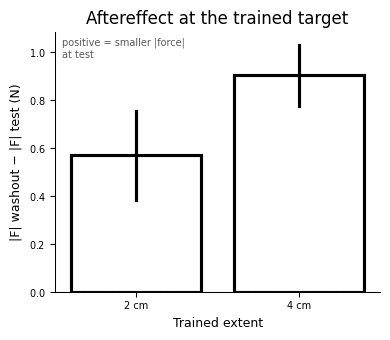

T-test trained 2 cm AE vs 0: p-value: 0.01798473233187649, t-stat: 3.0732666379514857, df: 7
T-test trained 4 cm AE vs 0: p-value: 0.0002005329234477422, t-stat: 7.060417404479313, df: 7
T-test trained-target AE 4 cm vs 2 cm (N): p-value: 0.0878945200872758, t-stat: 1.9822135165791774, df: 7
Adaptation reached: 51% of complete at 2 cm, 52% at 4 cm
T-test trained-target AE 4 cm vs 2 cm (% of complete): p-value: 0.9470371387023436, t-stat: 0.068846557702024, df: 7


In [ ]:
# --- Panel A (v2): aftereffect at the trained target, by trained extent (force magnitude) ---
# One AE per subject × trained extent: pool flexion and extension, then washout |F| − test |F|.
# Complete adaptation under gain 2 = half the washout force (printed below).

df = subjs_correct.loc[subjs_correct['epoch'].isin(['Washout', 'Test'])].copy()
df = df.loc[df['condition'] == df['adaptation_condition']].copy()  # trained target only
df['force_magnitude'] = df['producedForce2'].abs()
df['train_extent'] = df['adaptation_condition'].abs().astype(int)  # 2 or 4

epoch_pool = (
    df.groupby(['subNum', 'train_extent', 'epoch'], observed=True)['force_magnitude']
    .mean()
    .unstack('epoch')
)
epoch_pool['AE_magnitude'] = epoch_pool['Washout'] - epoch_pool['Test']
epoch_pool['complete_adaptation'] = epoch_pool['Washout'] / 2  # gain 2 → half the force
epoch_pool['percent_complete'] = 100 * epoch_pool['AE_magnitude'] / epoch_pool['complete_adaptation']
summary_trained = epoch_pool.reset_index()

extent_order = [2, 4]

fig, ax = plt.subplots(figsize=(4, 3.5))

sns.barplot(
    data=summary_trained,
    x='train_extent',
    y='AE_magnitude',
    order=extent_order,
    errorbar='se',
    legend=False,
    ax=ax,
    color='black',
    fill=False,
)

ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
ax.set_title('Aftereffect at the trained target')
ax.set_xlabel('Trained extent')
ax.set_xticks(range(len(extent_order)))
ax.set_xticklabels([f'{extent} cm' for extent in extent_order])
ax.set_ylabel('|F| washout − |F| test (N)')
ax.annotate(
    'positive = smaller |force|\nat test',
    xy=(0.02, 0.98),
    xycoords='axes fraction',
    va='top',
    ha='left',
    fontsize=7,
    color='0.35',
)

sns.despine()
plt.tight_layout()
plt.savefig(path_figs + 'summary_v2_panel_A_trained_target.pdf', bbox_inches='tight')
plt.show()

trained_wide = summary_trained.pivot(index='subNum', columns='train_extent', values='AE_magnitude')
percent_wide = summary_trained.pivot(index='subNum', columns='train_extent', values='percent_complete')

# statistical test:
# aftereffect at each trained extent vs 0
for extent in extent_order:
    result = stats.ttest_1samp(trained_wide[extent], 0)
    print(
        f"T-test trained {extent} cm AE vs 0: p-value: {result.pvalue}, "
        f"t-stat: {result.statistic}, df: {result.df}"
    )

# 4 cm vs 2 cm, in newtons and as a fraction of complete adaptation
result = stats.ttest_rel(trained_wide[4], trained_wide[2])
print(
    f"T-test trained-target AE 4 cm vs 2 cm (N): p-value: {result.pvalue}, "
    f"t-stat: {result.statistic}, df: {result.df}"
)
print(
    f"Adaptation reached: {percent_wide[2].mean():.0f}% of complete at 2 cm, "
    f"{percent_wide[4].mean():.0f}% at 4 cm"
)
result = stats.ttest_rel(percent_wide[4], percent_wide[2])
print(
    f"T-test trained-target AE 4 cm vs 2 cm (% of complete): p-value: {result.pvalue}, "
    f"t-stat: {result.statistic}, df: {result.df}"
)

### Panel B (v2) — How local is the adaptation?

Three bars, ordered by distance from the trained target (within each participant, then average across subjects):

- **Trained target:** test target = trained target
- **Same side:** the other extent on the trained side
- **Opposite side:** both extents on the other side

Each step changes one thing (first extent, then side):

**Extent-specific component:** trained target > same side.
**Side-specific generalization:** same side > opposite side.
**Generalization:** same side and opposite side > 0.
**Sign of the opposite-side AE:** > 0 (less force) is a magnitude change and fits either gain or additive (Panel C separates them); < 0 (more force) would be a directional bias ("less flexion" = "more extension").

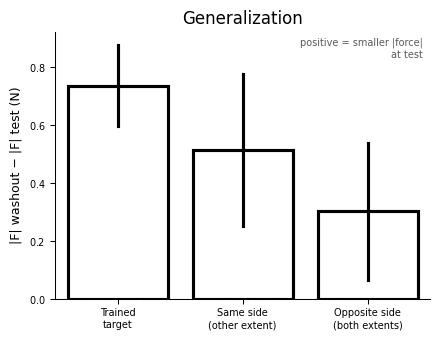

T-test trained target vs same side: p-value: 0.17274725824541454, t-stat: 1.5182372905956518, df: 7
T-test same side vs opposite side: p-value: 0.04923629039638115, t-stat: 2.3750899461174453, df: 7
T-test same side vs 0: p-value: 0.0905236033400724, t-stat: 1.9622162712708242, df: 7
T-test opposite side vs 0: p-value: 0.2410870776758838, t-stat: 1.280730570742087, df: 7


In [ ]:
# --- Panel B (v2): trained target vs same-side other extent vs opposite side (force magnitude) ---
# One AE per subject × target group: pool conditions, then washout |F| − test |F|.

df = subjs_correct.loc[subjs_correct['epoch'].isin(['Washout', 'Test'])].copy()
df['force_magnitude'] = df['producedForce2'].abs()
same_side = np.sign(df['condition']) == np.sign(df['adaptation_condition'])
df['target_group'] = np.where(
    df['condition'] == df['adaptation_condition'],
    'Trained target',
    np.where(same_side, 'Same side', 'Opposite side'),
)

epoch_pool = (
    df.groupby(['subNum', 'target_group', 'epoch'], observed=True)['force_magnitude']
    .mean()
    .unstack('epoch')
)
epoch_pool['AE_magnitude'] = epoch_pool['Washout'] - epoch_pool['Test']
summary_a = epoch_pool.reset_index()

group_order = ['Trained target', 'Same side', 'Opposite side']

fig, ax = plt.subplots(figsize=(4.5, 3.5))

sns.barplot(
    data=summary_a,
    x='target_group',
    y='AE_magnitude',
    order=group_order,
    errorbar='se',
    legend=False,
    ax=ax,
    color='black',
    fill=False,
)

ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
ax.set_title('Generalization')
ax.set_xlabel('')
ax.set_xticks(range(len(group_order)))
ax.set_xticklabels(['Trained\ntarget', 'Same side\n(other extent)', 'Opposite side\n(both extents)'])
ax.set_ylabel('|F| washout − |F| test (N)')
ax.annotate(
    'positive = smaller |force|\nat test',
    xy=(0.98, 0.98),
    xycoords='axes fraction',
    va='top',
    ha='right',
    fontsize=7,
    color='0.35',
)

sns.despine()
plt.tight_layout()
plt.savefig(path_figs + 'summary_v2_panel_B_generalization.pdf', bbox_inches='tight')
plt.show()

summary_a_wide = summary_a.pivot(index='subNum', columns='target_group', values='AE_magnitude')

# statistical test:
# extent specificity: trained target vs same-side other extent
result = stats.ttest_rel(summary_a_wide['Trained target'], summary_a_wide['Same side'])
print(
    f"T-test trained target vs same side: p-value: {result.pvalue}, "
    f"t-stat: {result.statistic}, df: {result.df}"
)

# side specificity: same-side other extent vs opposite side
result = stats.ttest_rel(summary_a_wide['Same side'], summary_a_wide['Opposite side'])
print(
    f"T-test same side vs opposite side: p-value: {result.pvalue}, "
    f"t-stat: {result.statistic}, df: {result.df}"
)

# generalization: untrained targets vs 0 (opposite side < 0 would mean a directional bias)
for group in ['Same side', 'Opposite side']:
    result = stats.ttest_1samp(summary_a_wide[group], 0)
    print(
        f"T-test {group.lower()} vs 0: p-value: {result.pvalue}, "
        f"t-stat: {result.statistic}, df: {result.df}"
    )

### Panel C (v2) — Gain or additive? Cross-extent transfer on the trained side

Untrained extent on the trained side only, so the extent-specific component (Panel B) enters neither bar:

- **Trained 2 → test 4**
- **Trained 4 → test 2**

Adapting at 4 cm takes a larger absolute force reduction than at 2 cm (Panel A); the trained-target AEs are printed again below.

**Additive (amount of force):** the larger reduction learned at 4 cm carries over as is, so **trained 4 → test 2 > trained 2 → test 4**.
**Gain (multiplicative):** the same fractional reduction is learned at either extent and scales with the tested force, so **trained 2 → test 4 > trained 4 → test 2**. Participants produce less than twice the 2 cm force at 4 cm, so gain predicts a ratio below 2.

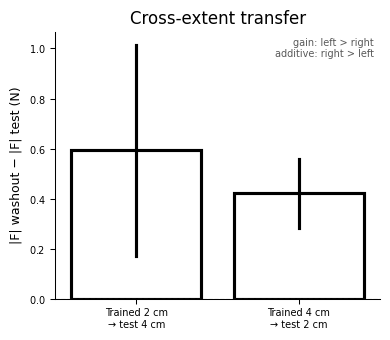

T-test trained 2→test 4 vs trained 4→test 2: p-value: 0.622661213768188, t-stat: 0.5146240756104726, df: 7
Trained-target AE: 4 cm = 0.902 N, 2 cm = 0.569 N
T-test trained-target AE 4 cm vs 2 cm: p-value: 0.0878945200872758, t-stat: 1.9822135165791774, df: 7


In [ ]:
# --- Panel C (v2): same side, untrained extent: trained 2 → test 4 vs trained 4 → test 2 ---
# One AE per subject × train/test extent: pool flexion and extension, then washout |F| − test |F|.

df = subjs_correct.loc[subjs_correct['epoch'].isin(['Washout', 'Test'])].copy()
df = df.loc[np.sign(df['condition']) == np.sign(df['adaptation_condition'])].copy()
df['force_magnitude'] = df['producedForce2'].abs()
df['train_extent'] = df['adaptation_condition'].abs().astype(int)  # 2 or 4
df['test_extent'] = df['condition'].abs().astype(int)

epoch_pool = (
    df.groupby(['subNum', 'train_extent', 'test_extent', 'epoch'], observed=True)['force_magnitude']
    .mean()
    .unstack('epoch')
)
epoch_pool['AE_magnitude'] = epoch_pool['Washout'] - epoch_pool['Test']
same_side_cells = epoch_pool.reset_index()

summary_c = same_side_cells.loc[same_side_cells['train_extent'] != same_side_cells['test_extent']].copy()
transfer_labels = {2: 'Trained 2 cm\n→ test 4 cm', 4: 'Trained 4 cm\n→ test 2 cm'}
summary_c['transfer'] = summary_c['train_extent'].map(transfer_labels)
transfer_order = [transfer_labels[2], transfer_labels[4]]

fig, ax = plt.subplots(figsize=(4, 3.5))

sns.barplot(
    data=summary_c,
    x='transfer',
    y='AE_magnitude',
    order=transfer_order,
    errorbar='se',
    legend=False,
    ax=ax,
    color='black',
    fill=False,
)

ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
ax.set_title('Cross-extent transfer')
ax.set_xlabel('')
ax.set_ylabel('|F| washout − |F| test (N)')
ax.annotate(
    'gain: left > right\nadditive: right > left',
    xy=(0.98, 0.98),
    xycoords='axes fraction',
    va='top',
    ha='right',
    fontsize=7,
    color='0.35',
)

sns.despine()
plt.tight_layout()
plt.savefig(path_figs + 'summary_v2_panel_C_cross_extent.pdf', bbox_inches='tight')
plt.show()

summary_c_wide = summary_c.pivot(index='subNum', columns='train_extent', values='AE_magnitude')

# statistical test:
# trained 2 → test 4 vs trained 4 → test 2 (gain: t > 0; additive: t < 0)
result = stats.ttest_rel(summary_c_wide[2], summary_c_wide[4])
print(
    f"T-test trained 2→test 4 vs trained 4→test 2: p-value: {result.pvalue}, "
    f"t-stat: {result.statistic}, df: {result.df}"
)

# premise for the additive prediction: larger absolute AE at the trained target when trained on 4 cm
trained_cells = same_side_cells.loc[same_side_cells['train_extent'] == same_side_cells['test_extent']]
trained_wide = trained_cells.pivot(index='subNum', columns='train_extent', values='AE_magnitude')
print(f"Trained-target AE: 4 cm = {trained_wide[4].mean():.3f} N, 2 cm = {trained_wide[2].mean():.3f} N")
result = stats.ttest_rel(trained_wide[4], trained_wide[2])
print(
    f"T-test trained-target AE 4 cm vs 2 cm: p-value: {result.pvalue}, "
    f"t-stat: {result.statistic}, df: {result.df}"
)